<a href="https://www.kaggle.com/code/nicapotato/us-flights-delays-2025-2026?scriptVersionId=364867556" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Delay Exploration — US Flights, 2025–2026
_Cancellations follow the calendar and a few carriers; late minutes follow the aircraft that arrived late_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [samuelpombourcq/us-flight-delays-and-cancellations-2025-2026](https://www.kaggle.com/datasets/samuelpombourcq/us-flight-delays-and-cancellations-2025-2026)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Carriers](#Carriers)** <br>
**5. [Calendar and Airports](#Calendar)** <br>
**6. [Cancel Reasons vs Late Minutes](#Causes)** <br>
**7. [What Moves the Cancel Rate](#Model)** <br>
**8. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one scheduled US flight: 11,730,351 flights, 1 Jan 2025 through 31 Aug 2026, 14 reporting airlines, 361 origin airports. The dataset also ships `airlines.csv`, `airports.csv`, a daily airport rollup, and a CSV sample. This notebook reads `flights.parquet` and checks the airline file against it.

Two fields are blank by construction. `cancellation_reason` is empty exactly when the flight operated. The five delay-cause minute columns are empty except on arrivals at least 15 minutes late (one late row is missing its cause minutes and is dropped from that sum). Those blanks stay null. Rates below use the rows where the field applies.

The question is what moves cancellations, and whether the same thing moves late arrivals.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import json
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` tests a crosstab and rank correlations; `sklearn` fits one linear model on a hold-out split. `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
PARQUET_NAME = "flights.parquet"
AIRLINE_FILE = "airlines.csv"
AIRPORT_FILE = "airports.csv"
KAGGLE_SLUG = "samuelpombourcq/us-flight-delays-and-cancellations-2025-2026"
DOW = {
    1: "Monday", 2: "Tuesday", 3: "Wednesday", 4: "Thursday",
    5: "Friday", 6: "Saturday", 7: "Sunday",
}
CAUSE_COLS = [
    "carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay",
]
EXPECTED = [
    "flight_date", "year", "month", "day_of_week", "airline_code", "airline",
    "tail_number", "flight_number", "origin", "origin_city", "origin_state",
    "dest", "dest_city", "dest_state", "sched_dep_time", "dep_time", "dep_delay",
    "dep_del15", "dep_time_block", "taxi_out", "wheels_off", "wheels_on", "taxi_in",
    "sched_arr_time", "arr_time", "arr_delay", "arr_del15", "cancelled",
    "cancellation_code", "cancellation_reason", "diverted", "sched_elapsed_time",
    "actual_elapsed_time", "air_time", "distance", "carrier_delay", "weather_delay",
    "nas_delay", "security_delay", "late_aircraft_delay",
]


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        hits = sorted(kaggle_root.rglob(basename))
        assert hits, f"no {basename} under {kaggle_root}"
        return hits[0]
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    root = Path(kagglehub.dataset_download(slug))
    hits = sorted(root.rglob(basename))
    assert hits, f"expected {basename} under {root}"
    return hits[0]


flight_path = resolve_file(PARQUET_NAME)
print("Flights:", flight_path)
df = pd.read_parquet(flight_path)
missing = set(EXPECTED) - set(df.columns)
assert not missing, sorted(missing)
assert df.shape == (11730351, 40), df.shape

df["flight_date"] = pd.to_datetime(df["flight_date"])
assert df["flight_date"].min() == pd.Timestamp("2025-01-01")
assert df["flight_date"].max() == pd.Timestamp("2026-08-31")
# 1 Jan 2025 was a Wednesday, and this file codes that day as 3, so 1=Monday ... 7=Sunday.
anchor = df.loc[df["flight_date"].eq(pd.Timestamp("2025-01-01")), "day_of_week"]
assert int(anchor.mode().iloc[0]) == 3
df["weekday"] = df["day_of_week"].map(DOW)
assert df["weekday"].notna().all()

cancelled = df["cancelled"] == 1
assert int(cancelled.sum()) == 206801
assert int(df.loc[~cancelled, "cancellation_reason"].isna().sum()) == int((~cancelled).sum())
assert int(df.loc[cancelled, "cancellation_reason"].isna().sum()) == 0
late = df["arr_del15"] == 1
assert int(df.loc[late, "carrier_delay"].isna().sum()) == 1
assert int(df.loc[df["arr_del15"].eq(0), "carrier_delay"].notna().sum()) == 0

airlines = pd.read_csv(resolve_file(AIRLINE_FILE))
assert int(airlines["flights"].sum()) == len(df)
airports = pd.read_csv(resolve_file(AIRPORT_FILE))
assert airports["iata_code"].nunique() == df["origin"].nunique() == 361

last_day = df.groupby(df["airline"].astype(str))["flight_date"].max()
assert last_day.loc["Spirit Airlines"] == pd.Timestamp("2026-05-01")
assert last_day.loc["Hawaiian Airlines"] == pd.Timestamp("2025-12-31")

print("Dataframe Dimension: {} Rows, {} Columns".format(*df.shape))
print(f"Dates: {df['flight_date'].min().date()} -> {df['flight_date'].max().date()}")
print(f"Airlines: {df['airline'].nunique()} | Origin airports: {df['origin'].nunique()}")
print(f"Cancelled: {int(cancelled.sum()):,} ({cancelled.mean():.2%}) | Diverted: {df['diverted'].mean():.2%}")
print(
    "Arrival 15+ min late, among flights with a flag: "
    f"{df['arr_del15'].mean():.2%} ({int(df['arr_del15'].isna().sum()):,} flags missing)"
)
print("Carrier last flight date:")
print(last_day.sort_values().to_string())
display(df.dtypes.to_frame("dtype"))
display(df.sample(5, random_state=7))

Flights: /kaggle/input/datasets/samuelpombourcq/us-flight-delays-and-cancellations-2025-2026/flights.parquet
Dataframe Dimension: 11730351 Rows, 41 Columns
Dates: 2025-01-01 -> 2026-08-31
Airlines: 14 | Origin airports: 361
Cancelled: 206,801 (1.76%) | Diverted: 0.30%
Arrival 15+ min late, among flights with a flag: 22.81% (242,001 flags missing)
Carrier last flight date:
airline
Hawaiian Airlines    2025-12-31
Spirit Airlines      2026-05-01
Alaska Airlines      2026-08-31
Allegiant Air        2026-08-31
American Airlines    2026-08-31
Delta Air Lines      2026-08-31
Envoy Air            2026-08-31
Frontier Airlines    2026-08-31
JetBlue Airways      2026-08-31
PSA Airlines         2026-08-31
Republic Airways     2026-08-31
SkyWest Airlines     2026-08-31
Southwest Airlines   2026-08-31
United Airlines      2026-08-31


,dtype
flight_date,datetime64[ns]
year,int16
month,int8
day_of_week,int8
airline_code,category
airline,category
tail_number,object
flight_number,Int32
origin,category
origin_city,object


,flight_date,year,month,day_of_week,airline_code,airline,tail_number,flight_number,origin,origin_city,origin_state,dest,dest_city,dest_state,sched_dep_time,dep_time,dep_delay,dep_del15,dep_time_block,taxi_out,wheels_off,wheels_on,taxi_in,sched_arr_time,arr_time,arr_delay,arr_del15,cancelled,cancellation_code,cancellation_reason,diverted,sched_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,weekday
4487814,2025-08-21,2025,8,4,UA,United Airlines,N889UA,2614,IAD,"Washington, DC",VA,CLE,"Cleveland, OH",OH,1735,1730,-5,0,1700-1759,12,1742,1836,5,1857,1841,-16,0,0,NaN,NaN,0,82,71,54,287,<NA>,<NA>,<NA>,<NA>,<NA>,Thursday
4416123,2025-08-17,2025,8,7,UA,United Airlines,N36280,1605,LAX,"Los Angeles, CA",CA,BWI,"Baltimore, MD",MD,2359,44,45,1,2300-2359,15,59,834,9,807,843,36,1,0,NaN,NaN,0,308,299,275,2329,28,0,0,0,8,Sunday
8389451,2026-03-17,2026,3,2,OO,SkyWest Airlines,N223JS,5053,DVL,"Devils Lake, ND",ND,DEN,"Denver, CO",CO,1808,1800,-8,0,1800-1859,13,1813,1840,32,1929,1912,-17,0,0,NaN,NaN,0,141,132,87,638,<NA>,<NA>,<NA>,<NA>,<NA>,Tuesday
3536456,2025-07-05,2025,7,6,OO,SkyWest Airlines,N743SK,4676,DEN,"Denver, CO",CO,LIT,"Little Rock, AR",AR,1725,1954,149,1,1700-1759,21,2015,2307,6,2043,2313,150,1,0,NaN,NaN,0,138,139,112,771,0,149,1,0,0,Saturday
8638553,2026-03-30,2026,3,1,AS,Alaska Airlines,N565AS,258,SEA,"Seattle, WA",WA,LIH,"Lihue, HI",HI,909,953,44,1,0900-0959,37,1030,1303,7,1237,1310,33,1,0,NaN,NaN,0,388,377,333,2700,0,0,0,0,33,Monday


**Code Explanation and Reasoning:** <br>
The parquet grain is asserted: 11,730,351 × 40, the date span, Wednesday 1 Jan 2025 coded as day 3, 206,801 cancellations, and the blank-reason rule. Cause minutes are asserted to be present on late arrivals except one row, and absent on on-time arrivals.

`airlines.csv` flight totals sum to the parquet row count. `airports.csv` has one row per origin code in the flights (361). Spirit's last flight in this file is 1 May 2026; Hawaiian's is 31 Dec 2025. Later months simply have no rows for those two carriers.

In [3]:
print("Null counts on timing fields (cancelled and diverted flights leave arrival fields empty):")
nulls = df.isnull().sum()
print(nulls[nulls > 0].sort_values(ascending=False).to_string())
operated = df.loc[(df["cancelled"] == 0) & df["arr_delay"].notna(), "arr_delay"]
print(
    f"Operated flights with an arrival delay: {len(operated):,} | "
    f"median {operated.median():.0f} min | mean {operated.mean():.1f} | "
    f"90th percentile {operated.quantile(0.9):.0f}"
)

Null counts on timing fields (cancelled and diverted flights leave arrival fields empty):
cancellation_code      11523550
cancellation_reason    11523550
security_delay          9109895
late_aircraft_delay     9109895
weather_delay           9109895
carrier_delay           9109895
nas_delay               9109895
arr_del15                242001
arr_delay                242001
air_time                 242001
actual_elapsed_time      242001
arr_time                 210822
taxi_in                  210822
wheels_on                210822
taxi_out                 205611
wheels_off               205611
dep_del15                198558
dep_delay                198558
dep_time                 197703
tail_number               27065
sched_elapsed_time            4
Operated flights with an arrival delay: 11,488,350 | median -6 min | mean 8.8 | 90th percentile 50


**Interpretation** <br>
About 1.76% of scheduled flights are cancelled and 0.30% are diverted. Among flights with an arrival-lateness flag, 22.8% arrive 15 minutes or more late.

On flights that operate and record an arrival delay, the median is 6 minutes early and the mean is +8.8 minutes. The 90th percentile is +50 minutes. The mean sits above the median because of that late tail. Cause-minute fields are empty on the flights that were not late; that is the reporting rule, and the null count on those columns is the on-time majority.

# **3. Univariate Distributions:** <a id="Univariate"></a>

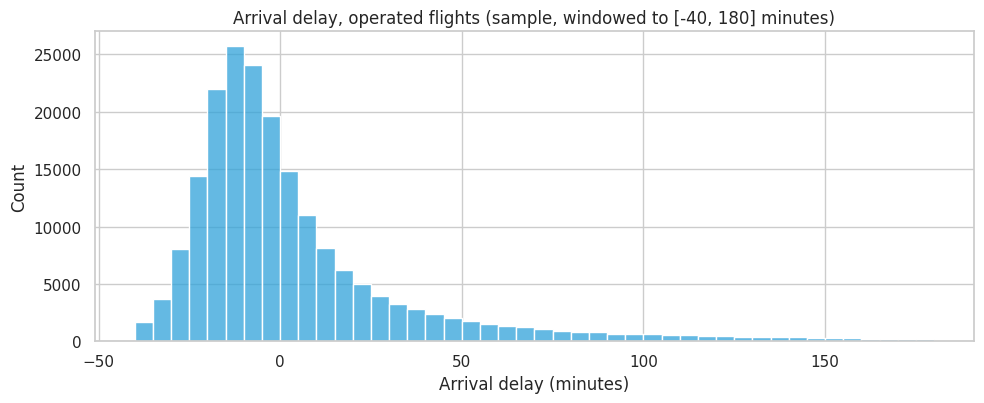

Drawn bars: 195,591 of 200,000 sampled delays fall inside the window


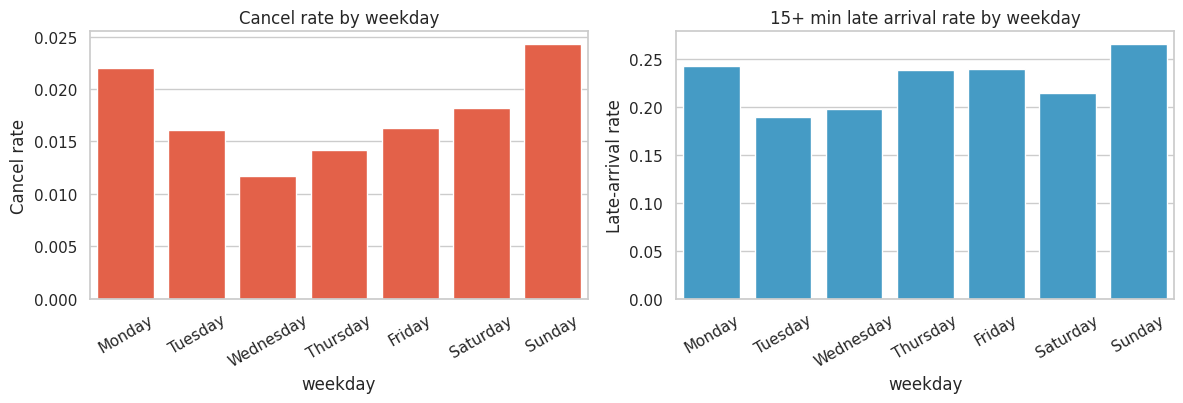

,flights,cancel_rate,arr15
weekday,,,
Monday,"1,762,225",2.20%,24.33%
Tuesday,"1,569,924",1.61%,18.91%
Wednesday,"1,601,901",1.17%,19.75%
Thursday,"1,752,986",1.42%,23.82%
Friday,"1,759,499",1.63%,23.99%
Saturday,"1,526,271",1.82%,21.48%
Sunday,"1,757,545",2.43%,26.57%


In [4]:
# Histogram window is drawn from a 200k sample so the full 11.7M rows are not scattered.
# Median, mean, and the 90th percentile above use every operated flight.
sample_delay = operated.sample(200_000, random_state=7)
window = sample_delay.loc[sample_delay.between(-40, 180)]
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.histplot(window, bins=44, color="#30a2da", ax=ax)
ax.set_title("Arrival delay, operated flights (sample, windowed to [-40, 180] minutes)")
ax.set_xlabel("Arrival delay (minutes)")
plt.tight_layout()
plt.show()
print(f"Drawn bars: {len(window):,} of {len(sample_delay):,} sampled delays fall inside the window")

weekday_order = list(DOW.values())
by_dow = (
    df.groupby("weekday", observed=True)
    .agg(
        flights=("cancelled", "size"),
        cancel_rate=("cancelled", "mean"),
        arr15=("arr_del15", "mean"),
    )
    .reindex(weekday_order)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(x=by_dow.index, y=by_dow["cancel_rate"], color="#fc4f30", ax=axes[0])
axes[0].set_title("Cancel rate by weekday")
axes[0].set_ylabel("Cancel rate")
axes[0].tick_params(axis="x", rotation=30)
sns.barplot(x=by_dow.index, y=by_dow["arr15"], color="#30a2da", ax=axes[1])
axes[1].set_title("15+ min late arrival rate by weekday")
axes[1].set_ylabel("Late-arrival rate")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(by_dow.style.format({"flights": "{:,.0f}", "cancel_rate": "{:.2%}", "arr15": "{:.2%}"}))

**Interpretation** <br>
The delay histogram is a spike just below zero — most operated flights arrive a few minutes early — with a long right tail past the plotted window. Sunday has the highest cancel rate (2.43%) and the highest late-arrival rate (26.6%). Wednesday is the quiet cancel day (1.17%). Tuesday has the lowest late-arrival rate (18.9%).

# **4. Carriers:** <a id="Carriers"></a>

Carrier rates, largest schedules first


,flights,cancel_rate,divert_rate,arr15,median_arr_delay
airline,,,,,
Southwest Airlines,"2,319,717",0.92%,0.27%,23.18%,-4
Delta Air Lines,"1,721,263",1.45%,0.28%,19.64%,-8
American Airlines,"1,641,071",2.15%,0.36%,25.88%,-5
SkyWest Airlines,"1,416,733",1.58%,0.34%,21.34%,-7
United Airlines,"1,354,575",0.99%,0.34%,21.58%,-6
Republic Airways,"592,269",4.12%,0.24%,21.32%,-9
Envoy Air,"517,046",2.27%,0.27%,20.22%,-7
Alaska Airlines,"473,194",1.18%,0.27%,21.66%,-4
PSA Airlines,"411,822",5.19%,0.30%,27.64%,-5


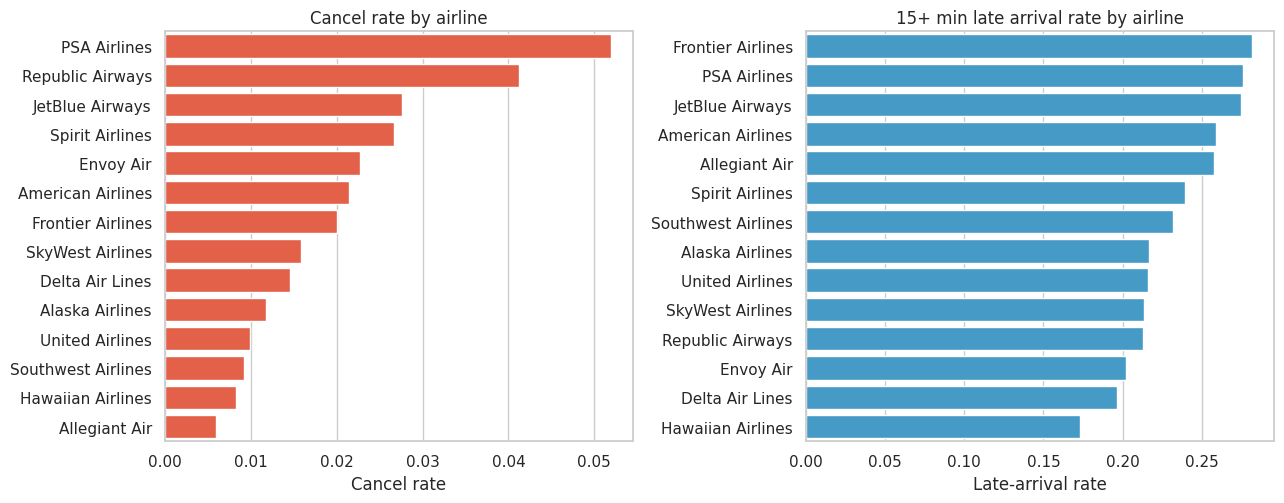

In [5]:
carriers = (
    df.groupby(df["airline"].astype(str), observed=True)
    .agg(
        flights=("cancelled", "size"),
        cancel_rate=("cancelled", "mean"),
        divert_rate=("diverted", "mean"),
        arr15=("arr_del15", "mean"),
        median_arr_delay=("arr_delay", "median"),
    )
    .sort_values("flights", ascending=False)
)
print("Carrier rates, largest schedules first")
display(
    carriers.style.format({
        "flights": "{:,.0f}",
        "cancel_rate": "{:.2%}",
        "divert_rate": "{:.2%}",
        "arr15": "{:.2%}",
        "median_arr_delay": "{:.0f}",
    }).background_gradient(subset=["cancel_rate", "arr15"], cmap="YlOrRd")
)

plot_carriers = carriers.reset_index().rename(columns={"airline": "airline"})
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
order_cancel = carriers.sort_values("cancel_rate", ascending=False).index.tolist()
order_late = carriers.sort_values("arr15", ascending=False).index.tolist()
sns.barplot(
    data=plot_carriers, y="airline", x="cancel_rate", order=order_cancel, color="#fc4f30", ax=axes[0],
)
axes[0].set_title("Cancel rate by airline")
axes[0].set_xlabel("Cancel rate")
axes[0].set_ylabel("")
sns.barplot(
    data=plot_carriers, y="airline", x="arr15", order=order_late, color="#30a2da", ax=axes[1],
)
axes[1].set_title("15+ min late arrival rate by airline")
axes[1].set_xlabel("Late-arrival rate")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretation** <br>
Cancel rate and late-arrival rate pick different carriers. PSA cancels 5.19% of flights and Republic 4.12%; Allegiant cancels 0.60% and Southwest 0.92%. Frontier's late-arrival rate is 28.2% and JetBlue's is 27.5%; Hawaiian is 17.3% and Delta is 19.6%. Every large carrier has a negative median arrival delay: the typical operated flight is early even where a quarter of flights are 15 minutes late.

Southwest is the largest schedule (2.32 million flights) with a low cancel rate and a mid-pack late-arrival rate (23.2%).

# **5. Calendar and Airports:** <a id="Calendar"></a>

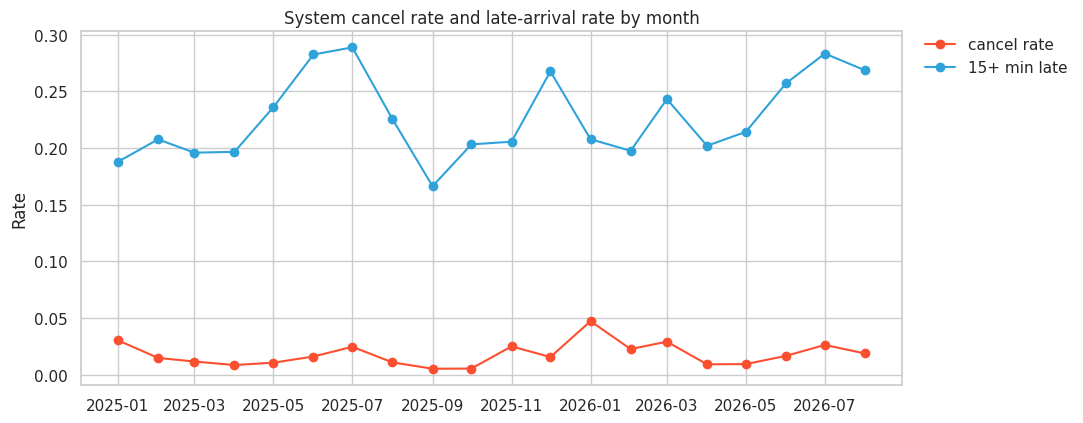

,year,month,flights,cancel_rate,arr15
0,2025,1,"539,747",3.02%,18.79%
1,2025,2,"504,884",1.47%,20.77%
2,2025,3,"600,872",1.15%,19.59%
3,2025,4,"583,950",0.84%,19.66%
4,2025,5,"605,648",1.05%,23.60%
5,2025,6,"611,575",1.59%,28.26%
6,2025,7,"631,428",2.45%,28.89%
7,2025,8,"602,378",1.08%,22.56%
8,2025,9,"562,439",0.51%,16.63%
9,2025,10,"605,844",0.53%,20.32%


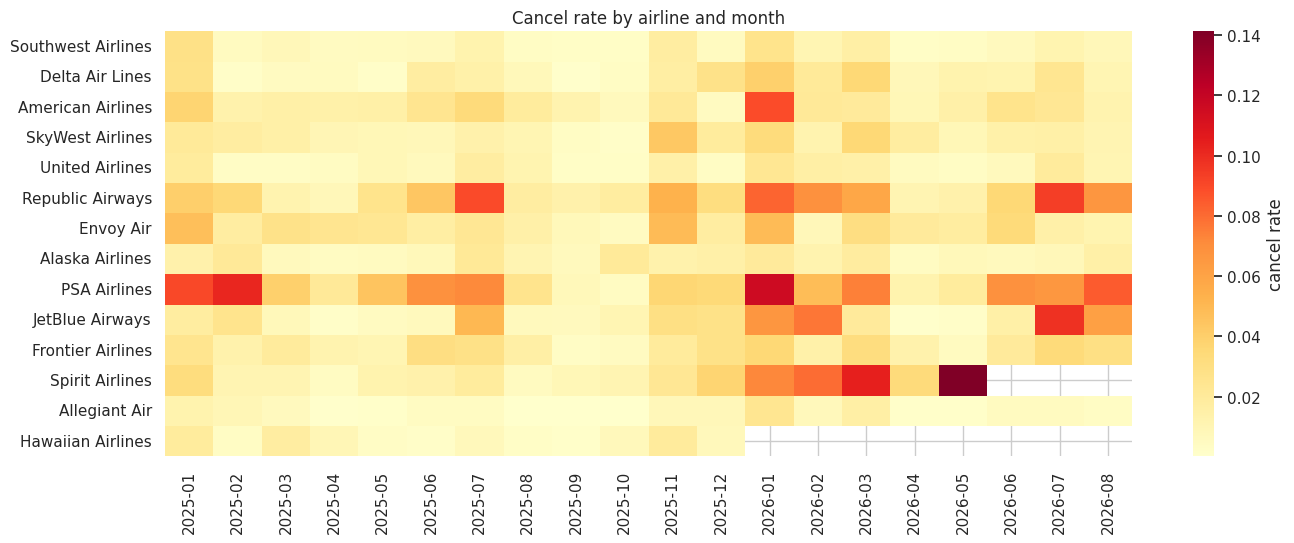

Highest cancel rate among origins with at least 50,000 departures


,flights,cancel_rate,arr15
origin,,,
DCA,"237,746",4.37%,27.72%
LGA,"224,650",4.26%,26.35%
JFK,"172,496",3.13%,25.17%
EWR,"200,975",3.12%,23.57%
DFW,"525,000",2.87%,28.44%
PHL,"166,730",2.86%,25.85%


Highest late-arrival rate among those origins


,flights,cancel_rate,arr15
origin,,,
DFW,"525,000",2.87%,28.44%
ORD,"573,580",2.32%,27.97%
DCA,"237,746",4.37%,27.72%
FLL,"149,669",1.97%,27.27%
MIA,"187,640",1.54%,26.48%
DAL,"118,315",1.51%,26.40%


In [6]:
monthly = (
    df.groupby(["year", "month"], as_index=False)
    .agg(flights=("cancelled", "size"), cancel_rate=("cancelled", "mean"), arr15=("arr_del15", "mean"))
)
monthly["ym"] = pd.to_datetime(
    dict(year=monthly["year"], month=monthly["month"], day=1)
)
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(monthly["ym"], monthly["cancel_rate"], marker="o", color="#fc4f30", label="cancel rate")
ax.plot(monthly["ym"], monthly["arr15"], marker="o", color="#30a2da", label="15+ min late")
ax.set_title("System cancel rate and late-arrival rate by month")
ax.set_ylabel("Rate")
park_legend(ax)
plt.tight_layout()
plt.show()
display(
    monthly.drop(columns=["ym"]).style.format({
        "flights": "{:,.0f}", "cancel_rate": "{:.2%}", "arr15": "{:.2%}",
    })
)

# Airline × month cancel rate. Missing cells are months a carrier did not fly.
rates = (
    df.groupby([df["airline"].astype(str), "year", "month"], observed=True)
    .agg(flights=("cancelled", "size"), cancel_rate=("cancelled", "mean"), arr15=("arr_del15", "mean"))
    .reset_index()
    .rename(columns={"airline": "airline"})
)
rates["ym"] = rates["year"].astype(str) + "-" + rates["month"].astype(int).astype(str).str.zfill(2)
assert len(rates) == 269, len(rates)
heat = (
    rates.pivot(index="airline", columns="ym", values="cancel_rate")
    .loc[carriers.index]
    .astype(float)
)
fig, ax = plt.subplots(figsize=(14, 5.6))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "cancel rate"})
ax.set_title("Cancel rate by airline and month")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

origins = (
    df.groupby(df["origin"].astype(str))
    .agg(flights=("cancelled", "size"), cancel_rate=("cancelled", "mean"), arr15=("arr_del15", "mean"))
)
big = origins.loc[origins["flights"] >= 50_000]
print("Highest cancel rate among origins with at least 50,000 departures")
display(big.sort_values("cancel_rate", ascending=False).head(6).style.format({
    "flights": "{:,.0f}", "cancel_rate": "{:.2%}", "arr15": "{:.2%}",
}))
print("Highest late-arrival rate among those origins")
display(big.sort_values("arr15", ascending=False).head(6).style.format({
    "flights": "{:,.0f}", "cancel_rate": "{:.2%}", "arr15": "{:.2%}",
}))

**Interpretation** <br>
January is the cancellation month. January 2026 cancels 4.71% of flights; January 2025 cancels 3.02%. September 2025 is the trough at 0.51%. Late arrivals peak in summer: July is about 28–29% in both years, while September 2025 is 16.6%. The two series do not peak in the same month.

Among origins with at least 50,000 departures, Washington National (DCA, 4.37%) and LaGuardia (LGA, 4.26%) lead cancellations. Dallas/Fort Worth leads large-airport late arrivals at 28.4%, with Chicago O'Hare at 28.0%. Honolulu is at the low end of that late-arrival list.

# **6. Cancel Reasons vs Late Minutes:** <a id="Causes"></a>

Cancellation reasons (cancelled flights only)


,cancellations,share
cancellation_reason,,
Weather,"132,935",64.3%
Carrier,"42,965",20.8%
National Air System,"30,775",14.9%
Security,126,0.1%


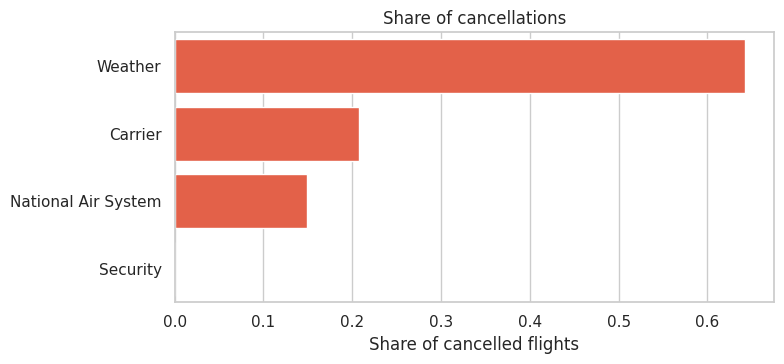

Late arrivals with cause minutes: 2,620,456


,minutes,share_of_late_minutes
carrier_delay,"62,812,624",32.6%
weather_delay,"12,283,605",6.4%
nas_delay,"41,004,513",21.3%
security_delay,"270,165",0.1%
late_aircraft_delay,"76,114,549",39.5%


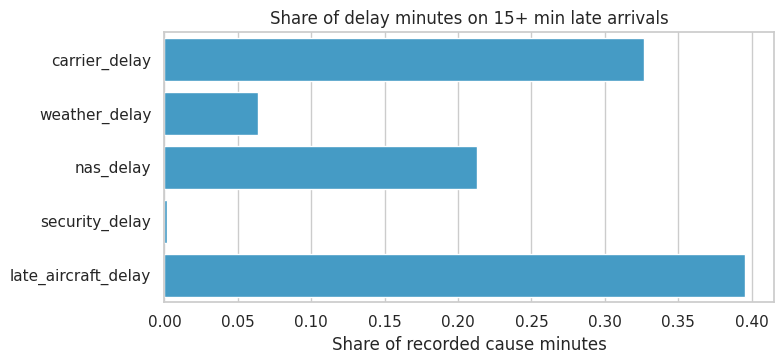

Distance vs arrival delay (n=200,000): Spearman rho=-0.013, p=1.795e-08


In [7]:
reason_counts = (
    df.loc[df["cancelled"] == 1, "cancellation_reason"]
    .astype(str)
    .value_counts()
    .rename("cancellations")
    .to_frame()
)
reason_counts["share"] = reason_counts["cancellations"] / reason_counts["cancellations"].sum()
print("Cancellation reasons (cancelled flights only)")
display(reason_counts.style.format({"cancellations": "{:,.0f}", "share": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(
    x=reason_counts["share"], y=reason_counts.index, color="#fc4f30", ax=ax,
)
ax.set_title("Share of cancellations")
ax.set_xlabel("Share of cancelled flights")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# One late arrival has no cause minutes. Drop that row; do not fill it with zero.
late_minutes = df.loc[df["arr_del15"] == 1, CAUSE_COLS].dropna(subset=["carrier_delay"])
minute_sum = late_minutes.sum()
minute_share = (minute_sum / minute_sum.sum()).rename("share_of_late_minutes").to_frame()
minute_share.insert(0, "minutes", minute_sum.astype(int))
print(f"Late arrivals with cause minutes: {len(late_minutes):,}")
display(minute_share.style.format({"minutes": "{:,.0f}", "share_of_late_minutes": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(
    x=minute_share["share_of_late_minutes"], y=minute_share.index, color="#30a2da", ax=ax,
)
ax.set_title("Share of delay minutes on 15+ min late arrivals")
ax.set_xlabel("Share of recorded cause minutes")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Rank correlation of distance and arrival delay on a 200k operated sample.
pair = df.loc[(df["cancelled"] == 0) & df["arr_delay"].notna(), ["distance", "arr_delay"]]
pair_sample = pair.sample(200_000, random_state=7)
rho_dist, p_dist = stats.spearmanr(pair_sample["distance"], pair_sample["arr_delay"])
print(f"Distance vs arrival delay (n={len(pair_sample):,}): Spearman rho={rho_dist:.3f}, p={p_dist:.3e}")

**Interpretation** <br>
Weather accounts for 64.3% of cancellations (132,935 of 206,801). Carrier is 20.8%, the national air system 14.9%, and security is 126 flights.

Delay minutes on late arrivals have a different mix. Late-arriving aircraft is 39.5% of those minutes, the carrier 32.6%, the national air system 21.3%, and weather 6.4%. Security is about 0.1%. A weather day removes the flight; a late inbound aircraft consumes the delay minutes of the flight that still operates.

Distance and arrival delay have Spearman ρ about −0.01 on a 200,000-flight sample. Stage length is not the delay axis.

# **7. What Moves the Cancel Rate:** <a id="Model"></a>

Airline-month rows: 269
Reference airline: Alaska Airlines
Reference month: 2025-01
Hold-out R^2, airline only: 0.380
Hold-out R^2, year-month only: 0.179
Hold-out R^2, airline + year-month: 0.537


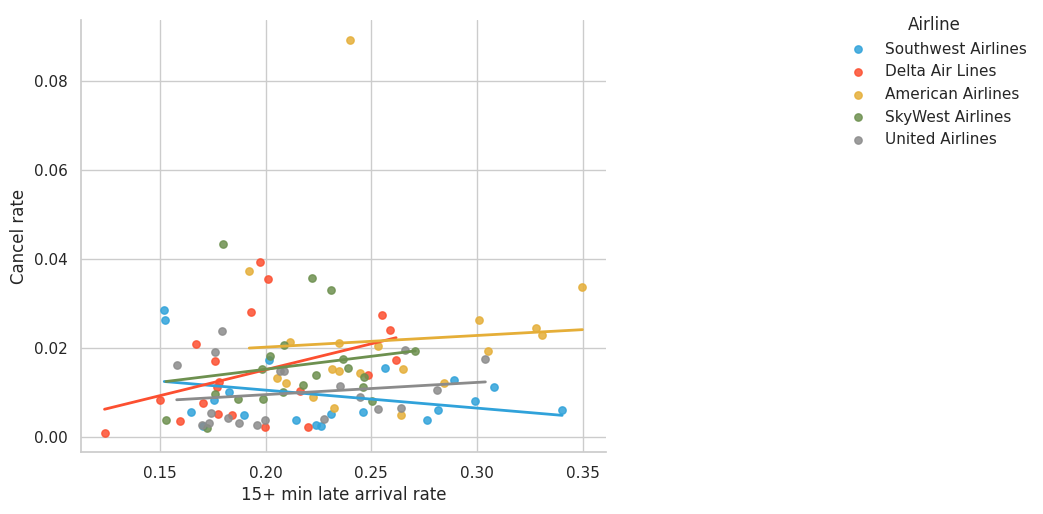

Lines are the five largest airlines by flight count. Each point is one airline-month.


In [8]:
# One row per airline-month. The outcome is that month's cancel rate, not a single flight.
# Reference levels are the first sorted airline and the first sorted year-month.
model = rates.copy()
y = model["cancel_rate"]
X_train, X_test, y_train, y_test = train_test_split(
    model[["airline", "ym"]], y, test_size=0.25, random_state=7,
)


def rate_r2(cols: list[str]) -> float:
    pipe = Pipeline([
        ("pre", ColumnTransformer([("cat", OneHotEncoder(drop="first"), cols)])),
        ("lr", LinearRegression()),
    ])
    pipe.fit(X_train[cols], y_train)
    return float(r2_score(y_test, pipe.predict(X_test[cols])))


print(f"Airline-month rows: {len(model)}")
print("Reference airline:", sorted(model["airline"].unique())[0])
print("Reference month:", sorted(model["ym"].unique())[0])
print(f"Hold-out R^2, airline only: {rate_r2(['airline']):.3f}")
print(f"Hold-out R^2, year-month only: {rate_r2(['ym']):.3f}")
print(f"Hold-out R^2, airline + year-month: {rate_r2(['airline', 'ym']):.3f}")

top5 = carriers.head(5).index.tolist()
scatter = rates.loc[rates["airline"].isin(top5)]
g = sns.lmplot(
    data=scatter,
    x="arr15",
    y="cancel_rate",
    hue="airline",
    hue_order=top5,
    height=5.2,
    aspect=1.25,
    ci=None,
    scatter_kws={"s": 28, "alpha": 0.85},
    line_kws={"lw": 2},
)
g.set_axis_labels("15+ min late arrival rate", "Cancel rate")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Airline", frameon=False)
plt.show()
print("Lines are the five largest airlines by flight count. Each point is one airline-month.")

**Interpretation** <br>
On the 269 airline-month rates, the carrier label alone has hold-out R² about 0.38. The year-month label alone is about 0.18. Together they reach about 0.54. Both the who and the when are in the cancel rate, and the carrier slice is the larger of the two.

The five largest airlines' monthly points show cancel rate and late-arrival rate rising together inside a carrier, on separate slopes. A bad month is often both a cancel month and a late month for that airline, which is a different statement from the system-wide calendar, where January leads cancellations and July leads late arrivals.

# **8. What It Means — Working Synthesis:** <a id="Synthesis"></a>

**What the table is:** <br>
11,730,351 US flights from 2025-01-01 through 2026-08-31, 14 airlines, 361 origins. Companion airline totals match the parquet. Spirit's rows stop on 2026-05-01 and Hawaiian's on 2025-12-31.

**Working takeaways:** <br>
- 1.76% of flights are cancelled and 0.30% diverted. 22.8% of flights with a lateness flag arrive 15 minutes or more late.
- Operated arrivals have median delay −6 minutes, mean +8.8, and a 90th percentile of +50. The typical flight is early; the mean is the tail.
- Weather is 64.3% of cancellations and 6.4% of late-arrival delay minutes. Late aircraft is 39.5% of those minutes, the carrier 32.6%, the national air system 21.3%.
- PSA cancels 5.19% and Allegiant 0.60%. Frontier's late-arrival rate is 28.2% and Hawaiian's is 17.3%. Median arrival delay is negative at every carrier.
- January 2026 cancels 4.71% of flights; September 2025 cancels 0.51%. July late-arrival rates are about 28–29%.
- Among large origins, DCA and LGA lead cancellations; DFW and ORD lead late arrivals.
- Airline-month cancel rates: hold-out R² about 0.38 from the carrier, 0.18 from the month, 0.54 from both. Distance and arrival delay have Spearman ρ about −0.01.

**Open follow-ups:** <br>
- Split the January cancel spike into weather versus carrier using the cancellation reason by month, now that the two reason mixes are separated.
- Read Spirit and Hawaiian only through their last flight date in this file.